# Avalanche day predictor: Davos

**Question:** how likely are natural avalanches around Davos on a day of the snow season (November-May) depending on parameters. How does a simple model compare with the official SLF forecasters?

1. **Data:** SLF avalanche observations + Open-Meteo weather, 1999-2019
2. **Features:** physical causes of avalanches (new snow, wind, weak layers, warming)
3. **Targets:** avalanche day, split into dry and wet
4. **Model:** one logistic regression for dry and one for wet avalanches, combined into one risk
5. **Test** on unseen winters and compare with the forecasters
6. **Use** the saved model to predict one day

**Overview: two models**

| Model | Avalanche type | Cause | Features |
|---|---|---|---|
| **Dry** | New snow slab | New snow overloads the snowpack | `snow_72h`, `snow_7d`, `snow_depth` |
| | Wind slab | Wind packs loose snow into slabs | `wind_gust`, `wind_snow` |
| | Weak-layer slab | New snow on a weak layer | `temp_gradient`, `snow_on_weak_layer` |
| | Release after storms | Fresh snow that warms up | `warming_after_snow` |
| | | Warm days lower the dry risk | `temp_max` |
| **Wet** | Wet snow | Warmth and sun make the snow wet | `temp_max`, `temp_min`, `temp_change`, `warm_sunny_day`, `snow_depth` |
| **Both** | | Avalanche cycles; season | `avalanche_yesterday`, one column per month |

**Which avalanches count:** natural only (not triggered by skiers or explosives), size 2 or larger (big enough to bury a person).


In [1]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

## 1. Data

**Avalanches:** SLF, *Snow avalanche data Davos, 1999-2019* ([doi:10.16904/envidat.134](https://www.envidat.ch/dataset/snow-avalanche-data-davos)), downloaded into `data/`. One row per day: avalanche counts and the official danger level (1-5). The same weather is less dangerous in November and May than in mid-winter (only 13 and 17 avalanche days in 21 winters), so the model gets one 0/1 column per month. The model learns one extra weight per month.

In [2]:
activity = pd.read_csv("data/avalanche_activity_data.csv", sep=";", parse_dates=["date"])
activity = activity[activity["date"].dt.month.isin([11, 12, 1, 2, 3, 4, 5])]
print(f"{len(activity)} days, {activity['date'].min().date()} to {activity['date'].max().date()}")

3530 days, 1998-11-20 to 2019-05-21


**Weather:** Open-Meteo archive (free). A weather model of the past on a ~10 km grid, calibrated at 2500 m where avalanches start. We keep October-June, because November features need the October weather. Downloaded once, then read from `data/`.

In [3]:
WEATHER_FILE = "data/weather_daily.csv"
DAILY = ["snowfall_sum", "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
         "wind_gusts_10m_max", "shortwave_radiation_sum"]


def fetch_one_winter(winter):
    """Weather from 1 Oct to 30 Jun (winter 2012 = 2011-2012, as in the SLF data)."""
    params = {"latitude": 46.80, "longitude": 9.84, "elevation": 2500, "timezone": "Europe/Zurich",
              "start_date": f"{winter - 1}-10-01", "end_date": f"{winter}-06-30",
              "daily": ",".join(DAILY), "hourly": "snow_depth"}  # snow depth only exists hourly
    response = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=60)
    response.raise_for_status()
    data = response.json()
    table = pd.DataFrame(data["daily"]).rename(columns={"time": "date"})
    hourly = pd.DataFrame(data["hourly"])
    hourly["date"] = hourly["time"].str[:10]  # "2012-02-01T13:00" -> "2012-02-01"
    table["snow_depth_cm"] = table["date"].map(hourly.groupby("date")["snow_depth"].mean() * 100)
    return table


if os.path.exists(WEATHER_FILE):
    weather = pd.read_csv(WEATHER_FILE)
else:
    weather = pd.concat([fetch_one_winter(w) for w in range(1999, 2020)], ignore_index=True)
    weather.to_csv(WEATHER_FILE, index=False)
print(f"{len(weather)} days of weather")

5738 days of weather


## 2. Features

Each feature stands for a physical cause. Only today and earlier days are used, never the future.

![Avalanche types](images/image.png)

**How each feature is computed**

| Feature | How |
|---|---|
| `snow_depth`, `wind_gust`, `temp_max`, `temp_min` | copied straight from the weather |
| `snow_72h`, `snow_7d` | sum of new snow over the last 3 or 7 days |
| `wind_snow` | wind gust x `snow_72h` |
| `warming_after_snow` | `snow_72h` x warming since yesterday (0 if colder) |
| `temp_change` | today's max temperature - yesterday's |
| `warm_sunny_day` | 1 if above 0 C and sunny (> 9 MJ/m2), otherwise 0 |
| `temp_gradient` | 14-day average of how cold it is / snow depth in m |
| `snow_on_weak_layer` | `snow_7d` if there was a weak layer (`temp_gradient` > 10) 7-27 days ago, otherwise 0 |
| `month_Nov` ... `month_May` | 1 in that month, otherwise 0 |
| `avalanche_yesterday` | from the avalanche data, not the weather (section 3) |


In [4]:
MONTHS = [11, 12, 1, 2, 3, 4, 5]
MONTH_COLUMNS = ["month_Nov", "month_Dec", "month_Jan", "month_Feb", "month_Mar", "month_Apr", "month_May"]


def compute_features(weather):
    """One row per day in (sorted), one row of features out."""
    weather = weather.sort_values("date").reset_index(drop=True)
    snow, t_max = weather["snowfall_sum"], weather["temperature_2m_max"]
    f = pd.DataFrame({"date": pd.to_datetime(weather["date"])})

    # Snow: rolling(3).sum() = today + the 2 days before
    f["snow_72h"] = snow.rolling(3, min_periods=1).sum()
    f["snow_7d"] = snow.rolling(7, min_periods=1).sum()
    f["snow_depth"] = weather["snow_depth_cm"]

    # Wind: strong wind moves loose snow into slabs
    f["wind_gust"] = weather["wind_gusts_10m_max"]
    f["wind_snow"] = f["wind_gust"] * f["snow_72h"]

    # Temperature gradient (C/m): ground under the snow ~0 C, surface ~ air temperature.
    # Cold air over thin snow (14-day average) grows weak crystals.
    # Checked against measured snow temperatures at Weissfluhjoch: correlation 0.85.
    air_cold = (-weather["temperature_2m_mean"]).clip(lower=0)
    snow_depth_m = (weather["snow_depth_cm"] / 100).clip(lower=0.1)  # avoid dividing by ~0
    f["temp_gradient"] = air_cold.rolling(14, min_periods=1).mean() / snow_depth_m
    # Weak layer 7-28 days ago (> 10 C/m, the rule of thumb) with new snow on top
    weak_layer = f["temp_gradient"].shift(7).rolling(21, min_periods=1).max()
    f["snow_on_weak_layer"] = f["snow_7d"] * (weak_layer > 10)

    # Warming
    f["temp_max"] = t_max
    f["temp_min"] = weather["temperature_2m_min"]
    f["temp_change"] = t_max.diff().fillna(0)  # today - yesterday
    f["warming_after_snow"] = f["snow_72h"] * f["temp_change"].clip(lower=0)
    # Sun only melts snow when it is warm: above 0 C and sunnier than a typical day (9 MJ/m2)
    f["warm_sunny_day"] = ((t_max > 0) & (weather["shortwave_radiation_sum"] > 9)).astype(int)

    # Season: one yes/no column per month, each month gets its own baseline risk
    for month, column in zip(MONTHS, MONTH_COLUMNS):
        f[column] = (f["date"].dt.month == month).astype(int)
    return f


features = compute_features(weather)

## 3. Targets

- **Avalanche day:** at least one **natural** avalanche of **size 2+** (big enough to bury a person). Natural only: we model the snowpack, not how many skiers are out.
- **Dry / wet day:** split by snow type, because they have different causes. One model each.
- **Avalanche yesterday** is a feature: avalanches come in cycles, and yesterday is already known.
- The official **danger level** is the human benchmark, never a feature.

In [5]:
def natural_size_2_plus(snow_type):
    return activity[f"{snow_type}.NATURAL.SIZE2"] + activity[f"{snow_type}.NATURAL.SIZE3"] + activity[f"{snow_type}.NATURAL.SIZE4"]


days = pd.DataFrame({
    "date": activity["date"],
    "winter": activity["year"],  # winter 2012 = 2011-2012
    "danger_level": activity["max.danger.corr"],
    "avalanche_day": (activity["NATURAL.SIZE_234"] >= 1).astype(int),
    "dry_day": (natural_size_2_plus("dry") >= 1).astype(int),
    "wet_day": (natural_size_2_plus("wet") >= 1).astype(int),
})

# Avalanche yesterday: look up the day before (0 if there is no record, e.g. 31 October)
avalanche_by_date = days.set_index("date")["avalanche_day"]
days["avalanche_yesterday"] = (days["date"] - pd.Timedelta(days=1)).map(avalanche_by_date).fillna(0)

data = days.merge(features, on="date")
print(f"{len(data)} days, avalanche days {data['avalanche_day'].mean():.0%} "
      f"(dry {data['dry_day'].mean():.0%}, wet {data['wet_day'].mean():.0%})")

3530 days, avalanche days 25% (dry 13%, wet 9%)


## 4. Train

- **Split by whole winters, at random:** 15 to learn from, 6 to test. Whole winters, because neighbouring days are almost identical.

**Logistic regression:** a weighted sum of the features is turned into a probability:

$$
p = \frac{1}{1 + e^{-(b_0 + w_1 x_1 + w_2 x_2 + \dots)}}
$$

**Binary cross-entropy:** the loss the weights are chosen to minimise, which punishes confident wrong predictions hardest:

$$
\text{BCE} = -\frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(p_i) + (1 - y_i) \log(1 - p_i) \right]
$$

**L-BFGS:** the optimiser. Like gradient descent it steps against the gradient, but it also estimates the curvature ($H_k$) and picks the step size ($\alpha_k$) itself, so there is no learning rate:

$$
w_{k+1} = w_k - \alpha_k\, H_k\, \nabla \text{Loss}(w_k)
$$

- **Combine:** P(avalanche) = 1 - (1 - P_dry)(1 - P_wet), the chance that at least one type happens.
- **Regularisation:** `C = 0.1` limits how large the weights may get (smaller C = smaller weights = less extreme probabilities; the default is 1).

In [6]:
DRY_FEATURES = ["snow_72h", "snow_7d", "snow_depth", "wind_snow", "wind_gust", "temp_gradient",
                "snow_on_weak_layer", "warming_after_snow", "temp_max", "avalanche_yesterday"] + MONTH_COLUMNS
WET_FEATURES = ["temp_max", "temp_min", "temp_change", "warm_sunny_day", "snow_depth",
                "avalanche_yesterday"] + MONTH_COLUMNS

all_winters = sorted(data["winter"].unique())
test_winters = np.random.default_rng(seed=0).choice(all_winters, size=6, replace=False)  # fixed seed
train = data[~data["winter"].isin(test_winters)].copy()
test = data[data["winter"].isin(test_winters)].copy()
print(f"Test winters: {sorted(int(w) for w in test_winters)}")


def train_logistic(rows, features, target, C):
    """Standardise (mean/std of the TRAINING rows) and fit by minimising the log loss + a penalty on large weights."""
    scaler = StandardScaler()
    model = LogisticRegression(C=C, max_iter=1000).fit(scaler.fit_transform(rows[features]), rows[target])
    return {"scaler": scaler, "model": model, "features": features}


def train_models(rows, C):
    return {"dry": train_logistic(rows, DRY_FEATURES, "dry_day", C),
            "wet": train_logistic(rows, WET_FEATURES, "wet_day", C)}


def predict_risk(models, rows):
    """Chance of at least one dry OR wet avalanche."""
    p = {}
    for kind, part in models.items():
        p[kind] = part["model"].predict_proba(part["scaler"].transform(rows[part["features"]]))[:, 1]
    return 1 - (1 - p["dry"]) * (1 - p["wet"])


Test winters: [1999, 2004, 2005, 2008, 2009, 2012]


In [7]:
C = 0.1  # regularisation: smaller weights, less extreme probabilities
models = train_models(train, C)
train["risk"] = predict_risk(models, train)
test["risk"] = predict_risk(models, test)

## 5. Risk levels

The model uses each level as often as the forecasters used theirs on the training winters: low ~ danger level 1, moderate ~ 2, considerable ~ 3, high ~ 4-5.

In [8]:
cutoffs = {
    "moderate": train["risk"].quantile((train["danger_level"] <= 1).mean()),
    "considerable": train["risk"].quantile((train["danger_level"] <= 2).mean()),
    "high": train["risk"].quantile((train["danger_level"] <= 3).mean()),
}


def risk_level(risk):
    """Turn a probability (0-1) into a word."""
    if risk >= cutoffs["high"]:
        return "high"
    if risk >= cutoffs["considerable"]:
        return "considerable"
    if risk >= cutoffs["moderate"]:
        return "moderate"
    return "low"


print({level: f"{value:.0%}" for level, value in cutoffs.items()})

{'moderate': '6%', 'considerable': '21%', 'high': '67%'}


## 6. Model vs forecasters

- **AUC:** how often an avalanche day gets a higher score than a quiet day (0.5 = coin flip, 1 = perfect).
- **Hit rate:** share of avalanche days with a warning (considerable or higher; forecasters: level 3+). **False alarms:** share of warnings with no avalanche.

In [9]:
avalanche = test["avalanche_day"] == 1
warnings = {"Forecasters": test["danger_level"] >= 3, "Our model": test["risk"] >= cutoffs["considerable"]}
scores = {"Forecasters": test["danger_level"], "Our model": test["risk"]}

results = pd.DataFrame({
    "AUC": [roc_auc_score(avalanche, scores[name]) for name in scores],
    "hit rate": [warnings[name][avalanche].mean() for name in scores],
    "false alarms": [(~avalanche[warnings[name]]).mean() for name in scores],
}, index=list(scores)).round(2)
results.to_csv("outputs/results.csv")
results

,AUC,hit rate,false alarms
Forecasters,0.66,0.63,0.66
Our model,0.72,0.66,0.63


**Luck with the test winters?** One split could be lucky, for example if the 6 test winters happen to be easy. So we repeat the whole thing 200 times: each time pick 6 other random test winters, train on the other 15, and compare the AUC of the model and the forecasters on those test winters. The average and the share of splits the model wins show whether the result holds.

The winters also differ in how avalanches were recorded: from 2015 to 2019 many more were found (35% avalanche days vs 22% before, and about twice as many avalanches per day), probably because recording improved. Random splits mix old and new winters into both train and test, so they don't show how well the model works on today's recording.

In [10]:
repeats = []
for seed in range(200):
    test_set = np.random.default_rng(seed).choice(all_winters, size=6, replace=False)
    tr, te = data[~data["winter"].isin(test_set)], data[data["winter"].isin(test_set)]
    repeats.append({"model": roc_auc_score(te["avalanche_day"], predict_risk(train_models(tr, C), te)),
                    "forecasters": roc_auc_score(te["avalanche_day"], te["danger_level"])})
repeats = pd.DataFrame(repeats)
print(f"Average AUC: model {repeats['model'].mean():.3f}, forecasters {repeats['forecasters'].mean():.3f}")
print(f"Model better in {(repeats['model'] > repeats['forecasters']).mean():.0%} of 200 splits")

Average AUC: model 0.738, forecasters 0.687
Model better in 100% of 200 splits


## 7. Plots

**ROC curve:** each point is one warning cut-off (e.g. "warn if risk ≥ 20%"), plotting the share of avalanche days caught against the share of quiet days wrongly flagged. The closer the curve gets to the top-left corner, the better; the diagonal is a coin flip.

**AUC:** the area under the ROC curve, one number for the whole curve. It equals the chance that a random avalanche day gets a higher risk than a random quiet day (0.5 = coin flip, 1 = perfect).

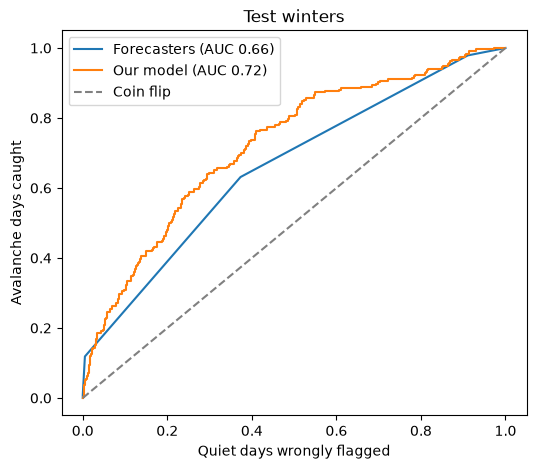

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, score in scores.items():
    false_rate, hit_rate, _ = roc_curve(avalanche, score)
    ax.plot(false_rate, hit_rate, label=f"{name} (AUC {roc_auc_score(avalanche, score):.2f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Coin flip")
ax.set(xlabel="Quiet days wrongly flagged", ylabel="Avalanche days caught", title="Test winters")
ax.legend()
fig.savefig("outputs/roc_comparison.png", dpi=150, bbox_inches="tight")

**Weights:** features are standardised, so a longer bar = a bigger effect. Right = more avalanches.

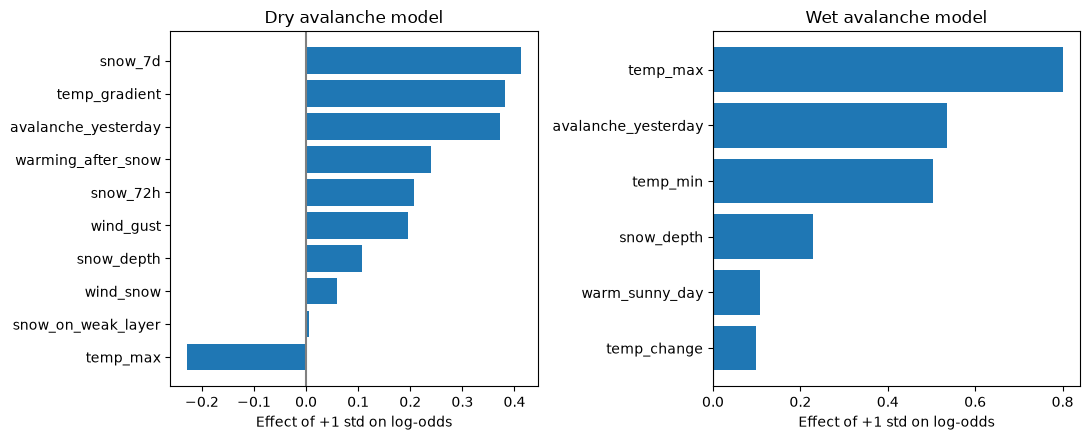

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (kind, part) in zip(axes, models.items()):
    weights = pd.Series(part["model"].coef_[0], index=part["features"]).drop(MONTH_COLUMNS).sort_values()
    ax.barh(weights.index, weights.values)
    ax.axvline(0, color="grey")
    ax.set(title=f"{kind.capitalize()} avalanche model", xlabel="Effect of +1 std on log-odds")
fig.tight_layout()
fig.savefig("outputs/feature_importance.png", dpi=150, bbox_inches="tight")

**Calibration:** when the model says 30%, do avalanches happen 30% of the time?

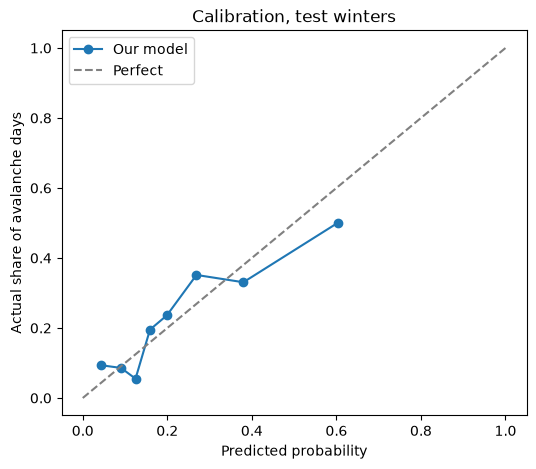

In [13]:
actual, predicted = calibration_curve(avalanche, test["risk"], n_bins=8, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(predicted, actual, "o-", label="Our model")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfect")
ax.set(xlabel="Predicted probability", ylabel="Actual share of avalanche days", title="Calibration, test winters")
ax.legend()
fig.savefig("outputs/calibration.png", dpi=150, bbox_inches="tight")

**One test winter, day by day:** model risk vs observed avalanche days (top) and the official danger level (bottom).

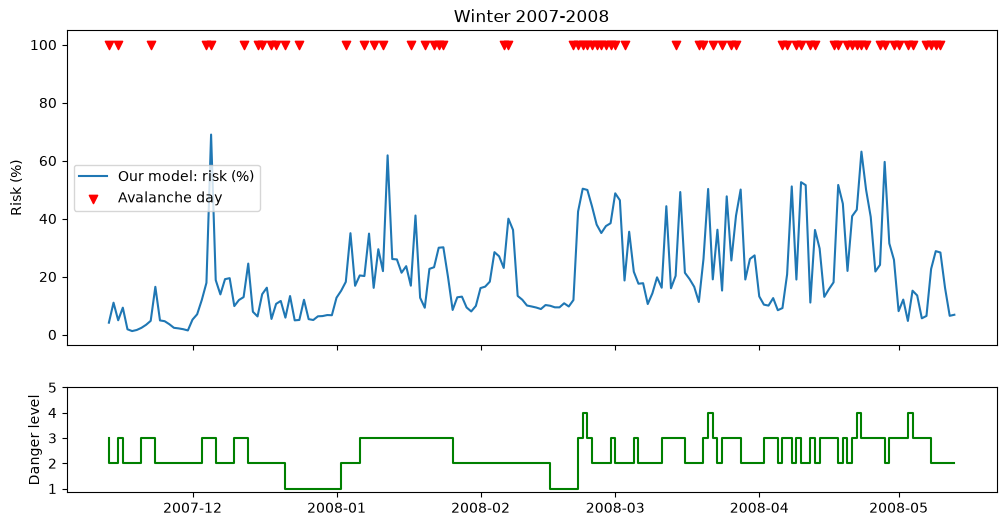

In [14]:
example = test.groupby("winter")["avalanche_day"].mean().idxmax()  # the most active test winter
winter = test[test["winter"] == example]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
top.plot(winter["date"], winter["risk"] * 100, label="Our model: risk (%)")
avalanche_days = winter[winter["avalanche_day"] == 1]
top.scatter(avalanche_days["date"], [100] * len(avalanche_days), marker="v", color="red", label="Avalanche day")
top.set(ylabel="Risk (%)", title=f"Winter {example - 1}-{example}")
top.legend(loc="center left")
bottom.step(winter["date"], winter["danger_level"], color="green")
bottom.set(ylabel="Danger level", yticks=[1, 2, 3, 4, 5])
fig.savefig("outputs/example_winter.png", dpi=150, bbox_inches="tight")

## 8. Save and use the model

Save the trained model and every past day (features + what happened). The agent (`agent.py`) only reads these files.

In [15]:
joblib.dump({"models": models, "cutoffs": cutoffs}, "data/model.joblib")
data.to_csv("data/all_days.csv", index=False)

saved = joblib.load("data/model.joblib")
day = data[data["date"] == "1999-02-23"]  # avalanche winter 1999, danger level 5, a TEST winter
risk = predict_risk(saved["models"], day)[0]
print(f"1999-02-23: risk {risk:.0%} -> {risk_level(risk)} (danger level {day['danger_level'].iloc[0]})")

1999-02-23: risk 95% -> high (danger level 5)


## Conclusions

- On unseen winters the model beats the official forecasters: average AUC **0.74 vs 0.69** over 200 random splits, better in **all** of them.
- **Dry** avalanches follow new snow (3-7 days), helped by wind and weak layers. **Wet** avalanches follow warmth. Avalanches come in cycles (avalanche yesterday).
- Every weight points in the physically expected direction. Several features overlap (wind x new snow and new snow, temp max and temp min), so single weights are rough, not exact.
- Regularisation (C = 0.1) makes the probabilities a little less extreme; the ranking (AUC) barely changes.

**Limitations**
- Modelled weather for one ~10 km grid cell; the snowpack gradient is estimated, not measured.
- One yes/no per day for the whole region: no slope direction, so wind loading and sun on south slopes cannot be separated. Tested and dropped: wind direction, models per slope direction, melt-freeze crusts.
- About twice as many avalanches were recorded per day after 2015; random winters put this in both train and test.
- Not a replacement for the official SLF avalanche bulletin.